In [1]:
#!source /n/holylfs05/LABS/arguelles_delgado_lab/Everyone/jbook/i3/build/env-shell.sh

In [2]:
from I3Tray import I3Tray
from icecube import icetray, dataio, dataclasses, simclasses
from icecube.LeptonInjector import weight_hnl_generation, load_generation_weighting_files, weight_hnl_lifetime_framewise
from icecube.LeptonInjector.oscnext_frame_objects_weighting import create_weight_dict
from icecube.LeptonInjector import hnl_weighting
from icecube.LeptonInjector.oscnext_tools_misc import UpdateFrameObject
import LeptonWeighter as LW

from icecube import icetray, dataio, dataclasses, LeptonInjector
from icecube import tableio, hdfwriter
from I3Tray import I3Units

from icecube.LeptonInjector import hdf5_to_feather
from collections import OrderedDict

try: from tqdm import tqdm
except: tqdm = lambda x: x
    
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import os
import glob as glob

/cvmfs/icecube.opensciencegrid.org/py3-v4.1.1/RHEL_8_x86_64/lib/python3.7/site-packages/ipykernel_launcher.py:1: UserWarning: Using `import I3Tray` or `from I3Tray import *` is now considered depricated. Please switch to using `from icecube.icetray import I3Tray`
  """Entry point for launching an IPython kernel.
/cvmfs/icecube.opensciencegrid.org/py3-v4.1.1/RHEL_8_x86_64/lib/python3.7/importlib/_bootstrap.py:219: RuntimeWarning: to-Python converter for std::vector<char, std::allocator<char> > already registered; second conversion method ignored.
  return f(*args, **kwds)
/cvmfs/icecube.opensciencegrid.org/py3-v4.1.1/RHEL_8_x86_64/lib/python3.7/importlib/_bootstrap.py:219: RuntimeWarning: to-Python converter for std::vector<std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> >, std::allocator<std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> > > > already registered; second conversion method ignored.
  return f(*args, **kwds)
/cvmfs/

In [3]:
loc_keys = [
    # true HNL variables
    "HNL_true_x",
    "HNL_true_y",
    "HNL_true_z",
    "HNL_true_energy",
    "HNL_true_zenith",
    "HNL_true_azimuth",
    "HNL_true_time",
    # true primary variables
    "true_x",
    "true_y",
    "true_z",
    "true_energy",
    "true_zenith",
    "true_azimuth",
    "true_time",
    # true first (DIS) cascade variables
    "casc0_true_x",
    "casc0_true_y",
    "casc0_true_z",
    "casc0_true_energy",
    "casc0_true_zenith",
    "casc0_true_azimuth",
    "casc0_true_time",
    # true second (HNL decay) cascade variables
    "casc1_true_x",
    "casc1_true_y",
    "casc1_true_z",
    "casc1_true_energy",
    "casc1_true_zenith",
    "casc1_true_azimuth",
    "casc1_true_time",
]

# function to get HNL true variables
def get_cascade_locations_framewise(frame):
    locs = {} #pd.DataFrame(columns=loc_keys)
    
    if not frame.Has("I3MCTree"):
        return False
    mctree = frame["I3MCTree"]
    p_true = mctree.primaries[0]

    p_daughters = mctree.get_daughters(p_true)
    assert len(p_daughters) == 2

    for p_daughter in p_daughters:
        if p_daughter.type == dataclasses.I3Particle.Hadrons:
            casc_0_true = p_daughter
        else:
            hnl_true = p_daughter

    hnl_daughters = mctree.get_daughters(hnl_true)
    assert len(hnl_daughters) > 0

    nan_energy = False

    for count_hnl_daughters, hnl_daughter in enumerate(hnl_daughters):
        if not count_hnl_daughters:
            casc_1_true = hnl_daughter
        else:
            assert casc_1_true.pos == hnl_daughter.pos
            if np.isnan(hnl_daughter.energy):
                nan_energy = True
            casc_1_true.energy = casc_1_true.energy + hnl_daughter.energy

    locs["true_x"] = dataclasses.I3Double(p_true.pos.x)
    locs["true_y"] = dataclasses.I3Double(p_true.pos.y)
    locs["true_z"] = dataclasses.I3Double(p_true.pos.z)
#     locs["true_energy"] = dataclasses.I3Double(p_true.energy)
#     locs["true_zenith"] = dataclasses.I3Double(p_true.dir.zenith)
#     locs["true_azimuth"] = dataclasses.I3Double(p_true.dir.azimuth)
#     locs["true_time"] = dataclasses.I3Double(p_true.time)

#     locs["HNL_true_x"] = dataclasses.I3Double(hnl_true.pos.x)
#     locs["HNL_true_y"] = dataclasses.I3Double(hnl_true.pos.y)
#     locs["HNL_true_z"] = dataclasses.I3Double(hnl_true.pos.z)
#     locs["HNL_true_energy"] = dataclasses.I3Double(hnl_true.energy)
#     locs["HNL_true_zenith"] = dataclasses.I3Double(hnl_true.dir.zenith)
#     locs["HNL_true_azimuth"] = dataclasses.I3Double(hnl_true.dir.azimuth)
#     locs["HNL_true_time"] = dataclasses.I3Double(hnl_true.time)

    locs["casc0_true_x"] = dataclasses.I3Double(casc_0_true.pos.x)
    locs["casc0_true_y"] = dataclasses.I3Double(casc_0_true.pos.y)
    locs["casc0_true_z"] = dataclasses.I3Double(casc_0_true.pos.z)
#     locs["casc0_true_energy"] = dataclasses.I3Double(casc_0_true.energy)
#     locs["casc0_true_zenith"] = dataclasses.I3Double(casc_0_true.dir.zenith)
#     locs["casc0_true_azimuth"] = dataclasses.I3Double(casc_0_true.dir.azimuth)
#     locs["casc0_true_time"] = dataclasses.I3Double(casc_0_true.time)

    locs["casc1_true_x"] = dataclasses.I3Double(casc_1_true.pos.x)
    locs["casc1_true_y"] = dataclasses.I3Double(casc_1_true.pos.y)
    locs["casc1_true_z"] = dataclasses.I3Double(casc_1_true.pos.z)
#     locs["casc1_true_energy"] = dataclasses.I3Double(casc_1_true.energy)
#     locs["casc1_true_zenith"] = dataclasses.I3Double(casc_1_true.dir.zenith)
#     locs["casc1_true_azimuth"] = dataclasses.I3Double(casc_1_true.dir.azimuth)
#     locs["casc1_true_time"] = dataclasses.I3Double(casc_1_true.time)

    return locs


In [4]:
# Read in I3 files:

#Should read det level files
def get_cascade_locations(files, nfiles=None):
    all_locs = pd.DataFrame(columns = loc_keys)
    rows = []
    if nfiles is None: nfiles = len(files)

    # Loop over the files
    for f in tqdm(files):
        i3file = dataio.I3File(f)
        
        # And loop through frames for this file
        while i3file.more():
            frame = i3file.pop_frame()
            
            if frame.Stop != icetray.I3Frame.DAQ: 
                continue
            new_row = get_cascade_locations_framewise(frame)
            rows.append(new_row)
#     all_locs = pd.DataFrame.from_dict(rows)
    return rows

In [5]:
signal_mc_dir = "/n/holylfs05/LABS/arguelles_delgado_lab/Lab/IceCube_MC/HNL/"
signal_keys = ['190311', '190312', '190313', '190314', '190315', '190316', '190317', '190318']

levels = ['Gen', 'Det', 'Phot', 'L1', 'L2']
Gen_files = []
Det_files = []
Phot_files = []
L1_files = []
L2_files = []


for skey in signal_keys:
    files = sorted(glob.glob(os.path.join(signal_mc_dir, skey, "L2/*.i3.zst")))
    L2_files.append(files)
    
    gen_files = sorted(glob.glob(os.path.join(signal_mc_dir, skey, "Gen/*.i3.zst")))
    Gen_files.append(gen_files)
    
    Photfiles = sorted(glob.glob(os.path.join(signal_mc_dir, skey, "Phot/*.i3.zst")))
    Phot_files.append(Photfiles)

    detfiles = sorted(glob.glob(os.path.join(signal_mc_dir, skey, "Det/*.i3.zst")))
    Det_files.append(detfiles)
    
    l1files = sorted(glob.glob(os.path.join(signal_mc_dir, skey, "L1/*.i3.zst")))
    Phot_files.append(l1files)


In [6]:
#Flatten the lists
L2_files = [item for sublist in L2_files for item in sublist]
L1_files = [item for sublist in L1_files for item in sublist]
Det_files = [item for sublist in Det_files for item in sublist]
Phot_files = [item for sublist in Phot_files for item in sublist]
Gen_files = [item for sublist in Gen_files for item in sublist]

In [7]:
signal_mc_dir = "/n/holylfs05/LABS/arguelles_delgado_lab/Lab/IceCube_MC/HNL/"
signal_keys = ['190311', '190312', '190313', '190314', '190315', '190316', '190317', '190318']

levels = ['Gen', 'Det', 'Phot', 'L1', 'L2']


# What's the base directory for your simulation set?
sim_base_dir = signal_mc_dir 

# When simulating sets at multiple masses, list the file prefixes for each mass here
levels = signal_keys

# dict for infilepaths
infiles = OrderedDict(zip(levels, [list() for level in levels]))
print(infiles)

# get the infilepaths
for key, item in infiles.items():
    print(key)  
    item.extend(
        glob.glob(os.path.join(sim_base_dir+ '/{}/L2/*.hdf5'.format(key))) #for test files
    )
    # We read in every file in you sim_base_dir with a key at the beginning of its file name
    # List the infile paths - use this to check the paths are correct
    print(item)

# read in the hdf files and store the dataframes
data = OrderedDict()

for key, item in infiles.items():   
    data[key] = hdf5_to_feather(item, keys=loc_keys, outfilepath="testfiles.feather")        

INFO:root:Keys to be extracted: dict_keys(['HNL_true_x', 'HNL_true_y', 'HNL_true_z', 'HNL_true_energy', 'HNL_true_zenith', 'HNL_true_azimuth', 'HNL_true_time', 'true_x', 'true_y', 'true_z', 'true_energy', 'true_zenith', 'true_azimuth', 'true_time', 'casc0_true_x', 'casc0_true_y', 'casc0_true_z', 'casc0_true_energy', 'casc0_true_zenith', 'casc0_true_azimuth', 'casc0_true_time', 'casc1_true_x', 'casc1_true_y', 'casc1_true_z', 'casc1_true_energy', 'casc1_true_zenith', 'casc1_true_azimuth', 'casc1_true_time'])


OrderedDict([('190311', []), ('190312', []), ('190313', []), ('190314', []), ('190315', []), ('190316', []), ('190317', []), ('190318', [])])
190311
['/n/holylfs05/LABS/arguelles_delgado_lab/Lab/IceCube_MC/HNL//190311/L2/3_1.hdf5', '/n/holylfs05/LABS/arguelles_delgado_lab/Lab/IceCube_MC/HNL//190311/L2/12_1.hdf5', '/n/holylfs05/LABS/arguelles_delgado_lab/Lab/IceCube_MC/HNL//190311/L2/7_1.hdf5', '/n/holylfs05/LABS/arguelles_delgado_lab/Lab/IceCube_MC/HNL//190311/L2/18_1.hdf5', '/n/holylfs05/LABS/arguelles_delgado_lab/Lab/IceCube_MC/HNL//190311/L2/8_1.hdf5', '/n/holylfs05/LABS/arguelles_delgado_lab/Lab/IceCube_MC/HNL//190311/L2/14_1.hdf5', '/n/holylfs05/LABS/arguelles_delgado_lab/Lab/IceCube_MC/HNL//190311/L2/0_1.hdf5', '/n/holylfs05/LABS/arguelles_delgado_lab/Lab/IceCube_MC/HNL//190311/L2/13_1.hdf5', '/n/holylfs05/LABS/arguelles_delgado_lab/Lab/IceCube_MC/HNL//190311/L2/10_1.hdf5', '/n/holylfs05/LABS/arguelles_delgado_lab/Lab/IceCube_MC/HNL//190311/L2/9_1.hdf5', '/n/holylfs05/LABS/arguel

100%|██████████| 18/18 [00:02<00:00,  7.31it/s]
INFO:root:Keys to be extracted: dict_keys(['HNL_true_x', 'HNL_true_y', 'HNL_true_z', 'HNL_true_energy', 'HNL_true_zenith', 'HNL_true_azimuth', 'HNL_true_time', 'true_x', 'true_y', 'true_z', 'true_energy', 'true_zenith', 'true_azimuth', 'true_time', 'casc0_true_x', 'casc0_true_y', 'casc0_true_z', 'casc0_true_energy', 'casc0_true_zenith', 'casc0_true_azimuth', 'casc0_true_time', 'casc1_true_x', 'casc1_true_y', 'casc1_true_z', 'casc1_true_energy', 'casc1_true_zenith', 'casc1_true_azimuth', 'casc1_true_time'])
100%|██████████| 20/20 [00:02<00:00,  6.80it/s]
INFO:root:Keys to be extracted: dict_keys(['HNL_true_x', 'HNL_true_y', 'HNL_true_z', 'HNL_true_energy', 'HNL_true_zenith', 'HNL_true_azimuth', 'HNL_true_time', 'true_x', 'true_y', 'true_z', 'true_energy', 'true_zenith', 'true_azimuth', 'true_time', 'casc0_true_x', 'casc0_true_y', 'casc0_true_z', 'casc0_true_energy', 'casc0_true_zenith', 'casc0_true_azimuth', 'casc0_true_time', 'casc1_true_

In [8]:
data['190311']

,HNL_true_x,HNL_true_y,HNL_true_z,HNL_true_energy,HNL_true_zenith,HNL_true_azimuth,HNL_true_time,true_x,true_y,true_z,...,casc0_true_azimuth,casc0_true_time,casc1_true_x,casc1_true_y,casc1_true_z,casc1_true_energy,casc1_true_zenith,casc1_true_azimuth,casc1_true_time,n_files
0,-173.908613,44.622002,-420.863159,6.469676,2.699742,6.232568,9786.095247,-173.908613,44.622002,-420.863159,...,5.744645,9786.095247,-221.394071,47.027658,-320.351419,6.470455,2.736133,6.125970,10157.030211,18
1,112.618915,-50.565236,-399.503587,8.206828,1.587989,1.990334,9837.119269,112.618915,-50.565236,-399.503587,...,2.234527,9837.119269,136.379922,-103.838899,-398.500617,8.207435,1.611823,2.001640,10031.738410,18
2,26.187604,-102.889310,-469.836384,5.911527,2.450138,0.098544,9725.368797,26.187604,-102.889310,-469.836384,...,0.160095,9725.368797,23.127065,-103.191888,-466.121095,5.912373,2.447974,0.093513,9741.459066,18
3,57.297312,-245.593433,-226.622503,224.052769,2.951788,1.149237,9765.962637,57.297312,-245.593433,-226.622503,...,1.237012,9765.962637,57.067579,-246.105722,-223.700106,224.052819,2.952149,1.150293,9775.888970,18
4,-197.975622,499.116336,-339.204745,25.873137,1.694232,1.254704,9708.355068,-197.975622,499.116336,-339.204745,...,1.179953,9708.355068,-202.243261,486.067780,-337.501475,25.873353,1.683450,1.263362,9754.500565,18
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5747,-36.429515,-81.835254,-482.920736,18.674016,1.814097,2.385225,9751.576224,-36.429515,-81.835254,-482.920736,...,2.376943,9751.576224,-31.513247,-86.474056,-481.242954,18.674280,1.809350,2.386299,9774.807360,18
5748,-236.782846,-444.625581,-454.585177,106.639888,2.377622,3.352680,9641.499899,-236.782846,-444.625581,-454.585177,...,3.342701,9641.499899,-234.327177,-444.099380,-451.963765,106.639925,2.378293,3.350589,9653.609244,18
5749,-89.241176,-21.871526,-194.453894,6.258940,1.827602,1.529800,9729.797300,-89.241176,-21.871526,-194.453894,...,1.494060,9729.797300,-90.022396,-40.916719,-189.448345,6.259736,1.852529,1.515214,9795.542803,18
5750,-313.902214,90.087581,-442.840357,393.191941,2.523757,0.500557,9628.625944,-313.902214,90.087581,-442.840357,...,0.475062,9628.625944,-330.881395,80.799517,-415.606628,393.192154,2.523660,0.501698,9740.070142,18


Text(0.5, 0, 'z coordinate')

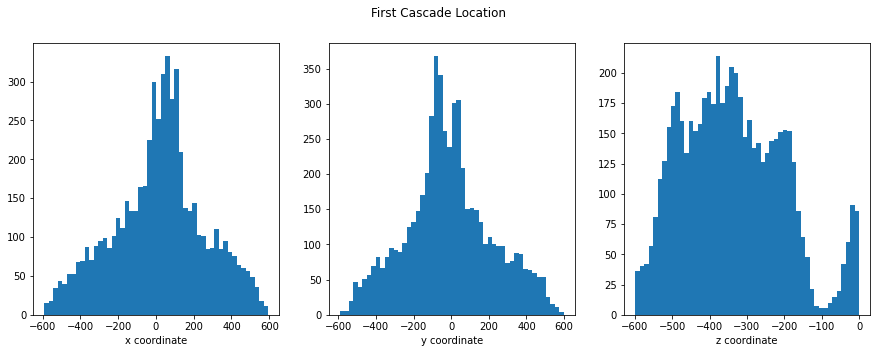

In [9]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15,5))
fig.suptitle('First Cascade Location')

ax1.hist(data['190311']['casc0_true_x'], bins = 50, label='Gen')
ax1.set_xlabel('x coordinate')

ax2.hist(data['190311']['casc0_true_y'], bins = 50, label='Gen')
ax2.set_xlabel('y coordinate')

ax3.hist(data['190311']['casc0_true_z'], bins = 50, label='Gen')
ax3.set_xlabel('z coordinate')

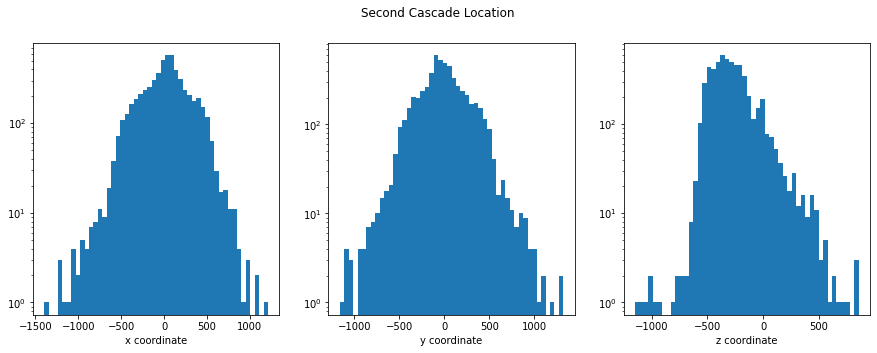

In [12]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15,5))
fig.suptitle('Second Cascade Location')

ax1.hist(data['190311']['casc1_true_x'], bins = 50, label='Gen')
ax1.set_xlabel('x coordinate')

ax2.hist(data['190311']['casc1_true_y'], bins = 50, label='Gen')
ax2.set_xlabel('y coordinate')

ax3.hist(data['190311']['casc1_true_z'], bins = 50, label='Gen')
ax3.set_xlabel('z coordinate')

ax1.set_yscale('log')
ax2.set_yscale('log')
ax3.set_yscale('log')

In [38]:
 def is_contained(event):
    # Return false if x, y are outside the cylinder
    if (np.power(event[1]['casc0_true_x'], 2) + np.power(event[1]['casc0_true_y'], 2) > np.power(450, 2)):
        return False
    if (np.power(event[1]['casc1_true_x'], 2) + np.power(event[1]['casc1_true_y'], 2) > np.power(450, 2)):
        return False
    if(event[1]['casc0_true_z']>600 or event[1]['casc1_true_z']<-600):
        return False

    #Otherwise, return true
    return True

In [40]:
num_uncontained =0
num_contained=0
for i in data['190311'].iterrows():
    if is_contained(i):
        num_contained+=1
    else:
        num_uncontained+=1
print("Contained: ", num_contained)
print("uncontained: ", num_uncontained)
print("Percent Contained at L2: ", num_contained/(num_contained+num_uncontained))
        

Contained:  3882
uncontained:  1870
Percent Contained at L2:  0.6748956884561892
